w(0) = 1.0000   w crosses zero at 2ln2 = 1.38629   W_max = 0.5000
kappa = 0.3:   S = sqrt(1 - 2*0.3) = 0.632456

a_minus = -log((1 ± S)/2) = 0.20306
  W(2a) = 0.300000                 (equals kappa = 0.3)
  U(0)  = 2 W(a) = 0.34890
  w(2a) = 0.516228   and   exp(-a) - kappa = 0.516228
  lam_e = 2w(2a)/(w(0)-w(2a)) = 2*0.516228/(1.000000-0.516228) = +2.13418

a_plus = -log((1 ± S)/2) = 1.69406
  W(2a) = 0.300000                 (equals kappa = 0.3)
  U(0)  = 2 W(a) = 0.97966
  w(2a) = -0.116228   and   exp(-a) - kappa = -0.116228
  lam_e = 2w(2a)/(w(0)-w(2a)) = 2*-0.116228/(1.000000--0.116228) = -0.20825

  closed form  lam(a-) = S(1+S)/(1-S(1+S)/2) = +2.13418
  closed form  lam(a+) = -S(1-S)/(1+S(1-S)/2) = -0.20825
  a_minus: min U inside = 0.300030, max U outside = 0.299982   (kappa = 0.3)
  a_plus: min U inside = 0.300065, max U outside = 0.299953   (kappa = 0.3)

kappa    a_minus   a_plus    U(0) small  U(0) large   lam(a_minus)  lam(a_plus)
0.1        0.05423   2.94150     0.10414 

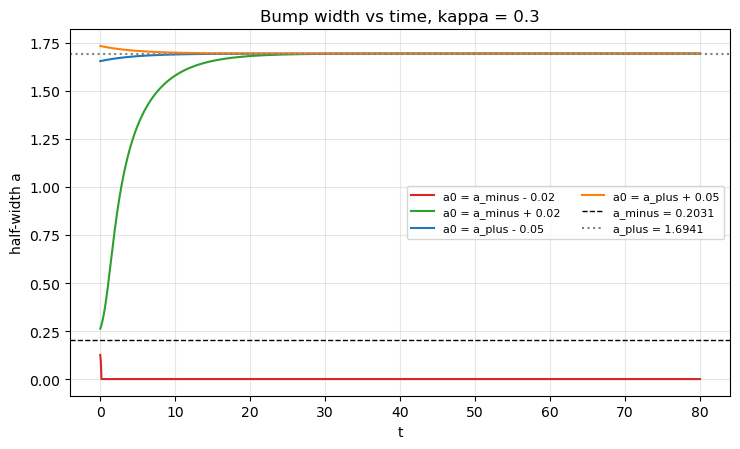

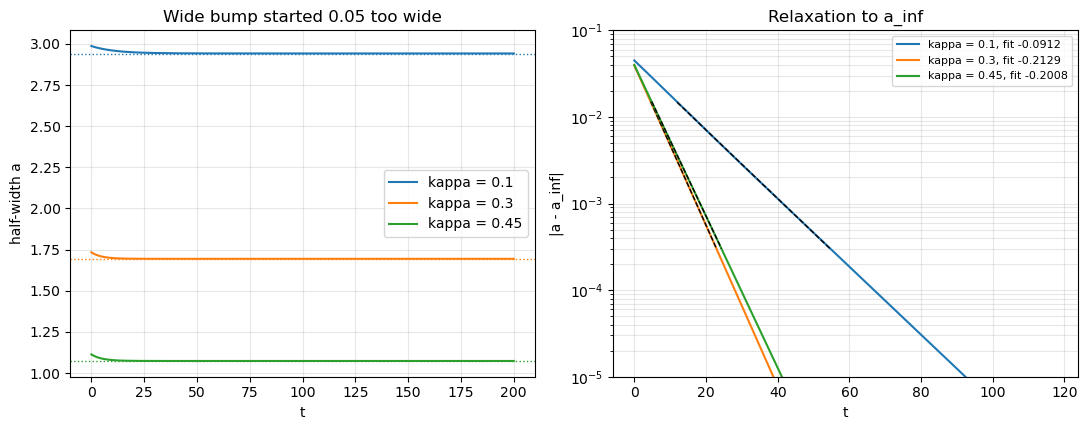

In [4]:
# APPM 4370/5370 HW5, Problem 3: stationary bumps in a Mexican-hat neural field.
%matplotlib inline

import numpy as np
from scipy.fft import rfft, irfft, next_fast_len
from scipy.special import expit
import matplotlib.pyplot as plt

plt.close("all")


def w(x):
    """w(x) = 2 exp(-|x|) - exp(-|x|/2)."""
    ax = np.abs(x)
    e1 = np.exp(-ax)              # exp(-|x|)
    e2 = np.exp(-ax/2)            # exp(-|x|/2)
    return 2*e1 - e2


def W(x):
    ax = np.abs(x)
    e2 = np.exp(-ax/2)
    e1 = np.exp(-ax)
    return np.sign(x) * 2*(e2 - e1)


def widths(kappa):
    S = np.sqrt(1 - 2*kappa)
    a_minus = -np.log((1 + S)/2)      # narrow bump, unstable
    a_plus = -np.log((1 - S)/2)       # wide bump, stable
    return a_minus, a_plus


def lam_even(a):
    w0 = w(0.0)
    w2 = w(2*a)
    numerator = 2*w2
    denominator = w0 - w2
    return numerator/denominator


#  the stationary bump
def U_stat(x, a):
    left = W(x + a)
    right = W(x - a)
    return left - right


#  space grid 
L = 20.0        # domain is [-L, L]
DX = 0.02
DT = 0.02
ETA = 100.0     # steepness of the smooth step

x = np.arange(-L, L + DX/2, DX)
N = len(x)



NFFT = next_fast_len(3*N - 2)
lag = np.arange(-(N-1), N)*DX
kernel = w(lag)
kernel_f = rfft(kernel, NFFT)


def conv(f):
    f_hat = rfft(f, NFFT)
    product_hat = f_hat*kernel_f
    product = irfft(product_hat, NFFT)
    centred = product[N-1:2*N-1]      
    return centred*DX               


def halfwidth(u, kappa):
    above = np.where(u > kappa)[0]
    if len(above) == 0:
        return 0.0
    i0 = above[0]
    i1 = above[-1]
    if i0 == 0:
        x_left = x[0]
    else:
        frac_left = (kappa - u[i0-1])/(u[i0] - u[i0-1])
        x_left = x[i0-1] + frac_left*DX
    if i1 == N-1:
        x_right = x[N-1]
    else:
        frac_right = (u[i1] - kappa)/(u[i1] - u[i1+1])
        x_right = x[i1] + frac_right*DX
    width = x_right - x_left
    return 0.5*width


def simulate(kappa, a0, T):
    u = U_stat(x, a0)
    nsteps = int(round(T/DT))
    t = np.arange(nsteps + 1)*DT
    a = np.zeros(nsteps + 1)
    a[0] = halfwidth(u, kappa)
    for n in range(nsteps):
        fired = expit(ETA*(u - kappa))        # smooth step H(u - kappa)
        drive = conv(fired)                   # int w(x-y) H(u(y)-kappa) dy
        du_dt = -u + drive                    # du/dt = -u + drive
        u = u + DT*du_dt                      # one Euler step
        a[n+1] = halfwidth(u, kappa)
    return t, a, u


k = 0.3
S = np.sqrt(1 - 2*k)
w0 = w(0.0)
zero = 2*np.log(2)
print(f"w(0) = {w0:.4f}   w crosses zero at 2ln2 = {zero:.5f}   W_max = {W(zero):.4f}")
print(f"kappa = {k}:   S = sqrt(1 - 2*{k}) = {S:.6f}")

am, ap = widths(k)
for name, a in (("a_minus", am), ("a_plus", ap)):
    two_a = 2*a
    W2 = W(two_a)
    U0 = 2*W(a)
    w2 = w(two_a)
    ema = np.exp(-a)
    print(f"\n{name} = -log((1 ± S)/2) = {a:.5f}")
    print(f"  W(2a) = {W2:.6f}                 (equals kappa = {k})")
    print(f"  U(0)  = 2 W(a) = {U0:.5f}")
    print(f"  w(2a) = {w2:.6f}   and   exp(-a) - kappa = {ema - k:.6f}")
    print(f"  lam_e = 2w(2a)/(w(0)-w(2a)) = 2*{w2:.6f}/({w0:.6f}-{w2:.6f}) = {lam_even(a):+.5f}")

lam_minus = S*(1 + S)/(1 - S*(1 + S)/2)
lam_plus = -S*(1 - S)/(1 + S*(1 - S)/2)
print(f"\n  closed form  lam(a-) = S(1+S)/(1-S(1+S)/2) = {lam_minus:+.5f}")
print(f"  closed form  lam(a+) = -S(1-S)/(1+S(1-S)/2) = {lam_plus:+.5f}")

# the profile must sit above kappa inside the bump and below it outside
xx = np.linspace(-15, 15, 300001)
for name, a in (("a_minus", am), ("a_plus", ap)):
    U = U_stat(xx, a)
    inside = np.abs(xx) <= a
    outside = np.abs(xx) > a
    print(f"  {name}: min U inside = {U[inside].min():.6f}, "
          f"max U outside = {U[outside].max():.6f}   (kappa = {k})")

print("\nkappa    a_minus   a_plus    U(0) small  U(0) large   lam(a_minus)  lam(a_plus)")
for kk in (0.1, 0.3, 0.45, 0.499):
    a1, a2 = widths(kk)
    print(f"{kk:<8} {a1:9.5f} {a2:9.5f} {2*W(a1):11.5f} {2*W(a2):12.5f} "
          f"{lam_even(a1):13.5f} {lam_even(a2):12.5f}")


T1 = 80.0
names = ["a_minus - 0.02", "a_minus + 0.02", "a_plus - 0.05", "a_plus + 0.05"]
starts = [am - 0.02, am + 0.02, ap - 0.05, ap + 0.05]
colors = ["tab:red", "tab:green", "tab:blue", "tab:orange"]

print("\n(i) start the field just off each bump, kappa = 0.3")
fig1, ax = plt.subplots(figsize=(7.5, 4.6))
for i in range(4):
    t, a, u = simulate(k, starts[i], T1)
    end = a[-1]
    if end == 0:
        fate = "dies"
    elif abs(end - ap) < 0.05:
        fate = f"settles on a_plus = {end:.4f}"
    else:
        fate = f"a = {end:.4f}"
    print(f"  {names[i]:<14} a0 = {starts[i]:.4f}  a(0) = {a[0]:.4f}  "
          f"a(end) = {end:.5f}  max u = {u.max():.4f}  ->  {fate}")
    ax.plot(t, a, color=colors[i], label="a0 = " + names[i])
ax.axhline(am, color="k", ls="--", lw=1, label=f"a_minus = {am:.4f}")
ax.axhline(ap, color="gray", ls=":", lw=1.5, label=f"a_plus = {ap:.4f}")
ax.set_xlabel("t")
ax.set_ylabel("half-width a")
ax.set_title("Bump width vs time, kappa = 0.3")
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3)
fig1.tight_layout()


T2 = 200.0
print("\n(ii) start the wide bump 0.05 too wide, fit |a(t) - a_inf| ~ exp(lam t)")
print("kappa    a_plus     a_inf      lam fit    lam(a_plus)   diff %")
fig2, axs = plt.subplots(1, 2, figsize=(11, 4.4))
for kk, c in zip((0.1, 0.3, 0.45), ["tab:blue", "tab:orange", "tab:green"]):
    _, a2 = widths(kk)
    t, a, _ = simulate(kk, a2 + 0.05, T2)

    a_inf = a[-1]
    dev = np.abs(a - a_inf)                       # |a(t) - a_inf|
    keep = (dev < 1.5e-2) & (dev > 3e-4) & (t < T2 - 20)
    # log dev = intercept + slope * t, and the slope is lam
    slope, intercept = np.polyfit(t[keep], np.log(dev[keep]), 1)

    lam = lam_even(a2)
    diff = 100*(slope - lam)/abs(lam)
    print(f"{kk:<8} {a2:9.5f} {a_inf:10.5f} {slope:10.5f} {lam:12.5f} {diff:8.2f}%")

    visible = dev > 1e-6
    axs[0].plot(t, a, color=c, label=f"kappa = {kk}")
    axs[0].axhline(a2, color=c, ls=":", lw=1)
    axs[1].semilogy(t[visible], dev[visible], color=c, label=f"kappa = {kk}, fit {slope:.4f}")
    t_fit = t[keep]
    axs[1].semilogy(t_fit, np.exp(intercept + slope*t_fit), "k--", lw=1)

axs[0].set_xlabel("t")
axs[0].set_ylabel("half-width a")
axs[0].set_title("Wide bump started 0.05 too wide")
axs[0].legend()
axs[0].grid(alpha=0.3)
axs[1].set_xlabel("t")
axs[1].set_ylabel("|a - a_inf|")
axs[1].set_title("Relaxation to a_inf")
axs[1].set_ylim(1e-5, 0.1)
axs[1].legend(fontsize=8)
axs[1].grid(alpha=0.3, which="both")
fig2.tight_layout()


#  edge law check
# da/dt = [W(2a) - kappa] / [w(0) - w(2a)]; its derivative at a± should equal lam(a±)
def edge_rate(a, kappa):
    numerator = W(2*a) - kappa
    denominator = w(0.0) - w(2*a)
    return numerator/denominator


print("\nedge law: slope of [W(2a)-kappa]/[w(0)-w(2a)] vs lam_e")
for kk in (0.1, 0.3, 0.45):
    a1, a2 = widths(kk)
    h = 1e-6
    slope_minus = (edge_rate(a1 + h, kk) - edge_rate(a1 - h, kk))/(2*h)
    slope_plus = (edge_rate(a2 + h, kk) - edge_rate(a2 - h, kk))/(2*h)
    print(f"  kappa = {kk}:  a_minus {slope_minus:+.5f} ({lam_even(a1):+.5f})   "
          f"a_plus {slope_plus:+.5f} ({lam_even(a2):+.5f})")

plt.show()
